# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1348 | Val: 323 | Test: 856


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 6.83e-05 | train loss 1.0709 acc 0.474 | val loss 0.8689 acc 0.576 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 6.83e-05 | train loss 0.9053 acc 0.551 | val loss 0.8389 acc 0.638 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 6.83e-05 | train loss 0.8493 acc 0.612 | val loss 0.8365 acc 0.607 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 6.83e-05 | train loss 0.7970 acc 0.609 | val loss 0.7824 acc 0.644 *


...

[ResNet-18 (scratch)] Epoch  51/100 | LR: 6.83e-06 | train loss 0.1766 acc 0.911 | val loss 0.4320 acc 0.842


[ResNet-18 (scratch)] Epoch  52/100 | LR: 6.83e-06 | train loss 0.1786 acc 0.915 | val loss 0.4468 acc 0.830


[ResNet-18 (scratch)] Epoch  53/100 | LR: 6.83e-06 | train loss 0.1705 acc 0.920 | val loss 0.4280 acc 0.839


[ResNet-18 (scratch)] Epoch  54/100 | LR: 6.83e-06 | train loss 0.1748 acc 0.912 | val loss 0.4425 acc 0.842


[ResNet-18 (scratch)] Epoch  55/100 | LR: 6.83e-06 | train loss 0.1824 acc 0.909 | val loss 0.4276 acc 0.858

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 55.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4089)


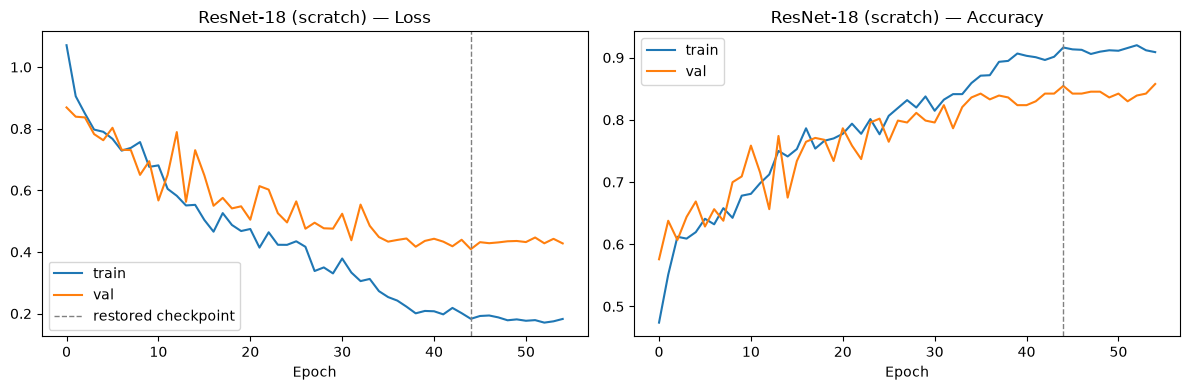

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.775


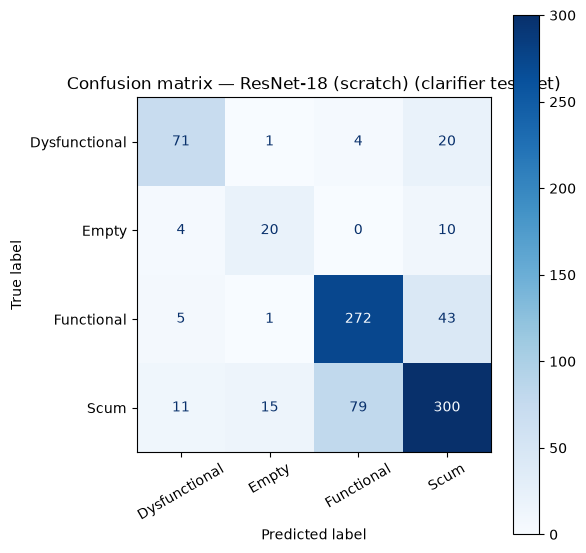

               precision    recall  f1-score   support

Dysfunctional      0.780     0.740     0.759        96
        Empty      0.541     0.588     0.563        34
   Functional      0.766     0.847     0.805       321
         Scum      0.804     0.741     0.771       405

     accuracy                          0.775       856
    macro avg      0.723     0.729     0.725       856
 weighted avg      0.777     0.775     0.774       856



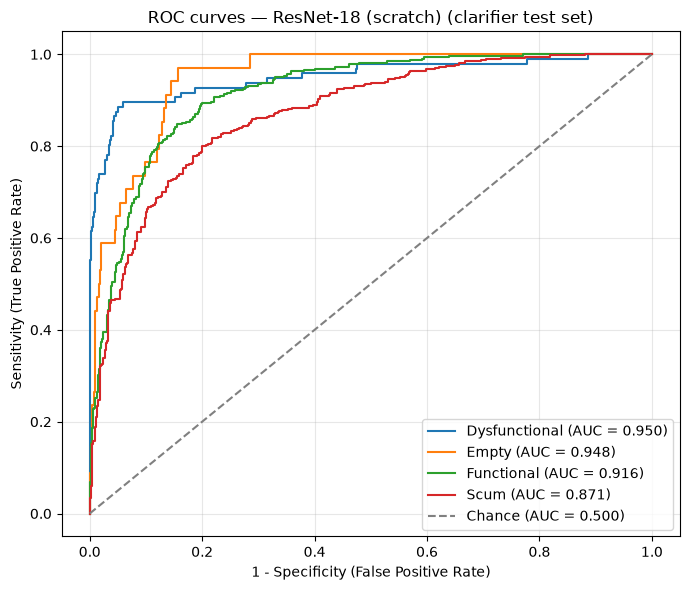

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.950
  Empty          : 0.948
  Functional     : 0.916
  Scum           : 0.871

Mean AUC (over 4/4 classes with test examples): 0.921


(np.float64(0.7745327102803738),
 {'Dysfunctional': 0.9498903508771931,
  'Empty': 0.9477243452125376,
  'Functional': 0.9159751943401171,
  'Scum': 0.8712655005337933})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_chronological.pt
